# CHCCS Enrollment Decline: A Data Exploration
Duke AIPI 510 Module 1 Project
Jim Redden


## 1. Introduction

Chapel Hill-Carrboro City Schools recently made the difficult decision to close an elementary school and is now redistricting. The board pointed to declining enrollment as one of the main drivers behind that decision.

My kids are in CHCCS, or will be soon, so this isn't an abstract question for me. For this Module 1 project, I wanted to use the data to look at that enrollment decline. What factors are actually contributing to the decline? And what might a deeper look at the data reveal that isn't obvious from the outside?

## 2. Data Sources & Context

Every source we're  using in this analysis is listed in `data_sources/INDEX.md`. Everything else we looked at while figuring out what to use — dead ends, background reading, stuff we considered and didn't need — is in `RESEARCH_APPENDIX.md`.

The primary data source for this analysis is NC DPI's School Report Card data. NC DPI publishes this as a bulk download for researchers: two ZIP files containing about 67 separate tables — enrollment, accountability results, per-pupil spending, and more — each one keyed by year and a school or district code so they can be joined together. It's not a single dataset so much as a whole warehouse of them, released together.

Out of those ~67 tables, we're starting with one: `rcd_adm`, which has Average Daily Membership — the state's official enrollment count — by year, back to 2006, at both the district and individual school level.


- **Masking rule:** any count under 10, or any percentage below 5% or above 95%, gets suppressed in the published tables. A district-wide number like CHCCS's total ADM won't be affected, but it matters if we ever look at a small school or a small subgroup.
- **Excluded LEAs:** nine specific agency codes (209, 269, 298, 299, 679, 996, 997, 998, 999) are left out of the ADM release entirely. Cross-referencing three of them against the NCES district directory (below) confirms they're federal or tribal-run schools, not regular NC districts: 209 is Cherokee Central Schools (Bureau of Indian Education), 269 is Fort Bragg, and 679 is Camp Lejeune (both Department of Defense). The other six weren't checked.

Beyond that, DPI doesn't publish a real methodology document for how ADM itself gets measured or calculated. The public-facing pages (FAQ, welcome letter, data sources guide) explain the letter-grade formula DPI gives to schools, not the underlying enrollment numbers. From a quick interview with someone that taught in CHCCS, I know that enrollment data collection and submission is typically managed by the schools data manager.


To compare enrollment against the number of school-age kids actually living in each district (Section 5), we also brought in Census population estimates: the Census Bureau's Small Area Income and Poverty Estimates (SAIPE) program publishes total population and population ages 5-17 for every school district, annually, 2019 through 2024.

SAIPE identifies districts with a federal NCES ID, which has no obvious relationship to DPI's own agency codes -- there's no formula to convert one to the other. To bridge them, we also pulled the NCES Common Core of Data (CCD) district directory, which lists both ID systems for the same district side by side. Matching IDs across datasets like this is its own kind of work, separate from the actual analysis, so that logic lives in its own file, `src/build_lea_population_crosswalk.py`, documented as crosswalk-only. It runs once and saves `data/lea_population_crosswalk.csv`; everything else in this notebook just reads that file rather than redoing the matching.

## 3. Loading the Data

Load the data and conduct initial exploration to understand the structure of the data, dimensions, data types, how missing values are represented, etc.


In [1]:
import pandas as pd

# Load the raw NC DPI enrollment data. This is every school and district in
# the state, not just CHCCS -- we'll narrow it down to CHCCS in the
# Preprocessing section. For now we just want to see what we're working with.
adm = pd.read_csv("../data_sources/nc_dpi_rcd_adm_2024-25.csv")

# Structure question #1 (Ch. 3): how big is this?
print("Shape (rows, columns):", adm.shape)

Shape (rows, columns): (62748, 4)


In [2]:
# Structure question #2: what do the actual rows look like?
adm.head()

,year,agency_code,category_code,avg_student_num
0,2006,010303,NaN,22
1,2006,010304,NaN,528
2,2006,010308,NaN,575
3,2006,010310,NaN,726
4,2006,010320,NaN,374


In [3]:
# Structure question #3: what data type is each column?
# (year and agency_code should be identifiers/text, avg_student_num should be numeric)
adm.dtypes

year                int64
agency_code        object
category_code      object
avg_student_num     int64
dtype: object

In [4]:
# Structure question #4: how are missing values represented here?
# isnull() only catches real NaNs -- it won't catch a blank string "" or a
# sentinel value, so we check both.
print("True NaNs per column:")
print(adm.isnull().sum())

print()
print("Empty-string values per column:")
print((adm == "").sum())

True NaNs per column:
year                   0
agency_code            0
category_code      53793
avg_student_num        0
dtype: int64

Empty-string values per column:
year               0
agency_code        0
category_code      0
avg_student_num    0
dtype: int64


In [5]:
# Descriptive statistics -- only avg_student_num is numeric, so this is the
# one column where mean/median/spread actually mean something here.
adm.describe()

,year,avg_student_num
count,62748.000000,6.274800e+04
mean,2015.693026,1.459234e+03
std,5.750197,2.680736e+04
min,2006.000000,0.000000e+00
25%,2011.000000,3.310000e+02
50%,2016.000000,5.120000e+02
75%,2021.000000,7.420000e+02
max,2025.000000,1.535687e+06


Note: 0 avg_student_num min means missing values are likely represented by 0 in some places

In [6]:
# The data dictionary's "table index" -- lists all ~67 tables in the NC DPI
# release, including rcd_adm, with a short description of each.
table_index = pd.read_csv("../data_sources/nc_dpi_report_card_data_dictionary_2024-25__table_index.csv")
print("Shape (rows, columns):", table_index.shape)

Shape (rows, columns): (66, 5)


In [7]:
table_index.head()

,rcd_filename,start_year,end_year,status,description
0,rcd_161,2009.0,2012.0,retired,College Completes
1,rcd_acc_aapart,2018.0,NaN,active,Accountabilty - Alternate Assessment Participa...
2,rcd_acc_act,2013.0,NaN,active,Accountability - Indicator Data - ACT
3,rcd_acc_awa,2018.0,NaN,active,Accountability - Indicator Data - ACT/Workkeys...
4,rcd_acc_cgr,2016.0,NaN,active,Accountability - Indicator Data - Cohort Gradu...


In [8]:
# The "SY24-25 columns" file -- one row per column, per table, describing
# what each field means. This is what tells us avg_student_num is a count
# of students, not something else.
sy2425_columns = pd.read_csv("../data_sources/nc_dpi_report_card_data_dictionary_2024-25__sy2425_columns.csv")
print("Shape (rows, columns):", sy2425_columns.shape)

Shape (rows, columns): (598, 7)


In [9]:
sy2425_columns.head()

,Table Name,Column Name,Column Type,Description,Code,Notes,Unnamed: 6
0,rcd_acc_pc,year,VARCHAR(4),YYYY (i.e. 2006 for the 2005/06 school year),k,NaN,NaN
1,rcd_acc_pc,agency_code,VARCHAR(6),010303/010LEA/NC-SEA,k,NaN,NaN
2,rcd_acc_pc,standard,VARCHAR(3),Standard. See acc_pc_standard table for detail,k,NaN,NaN
3,rcd_acc_pc,subject,VARCHAR(6),Subject,k,NaN,NaN
4,rcd_acc_pc,grade,VARCHAR(6),Grade,k,NaN,NaN


In [10]:
# "General rules" -- the masking/suppression rules and excluded-LEA list we
# already read by hand for the Context Questions in Section 2.
general_rules = pd.read_csv("../data_sources/nc_dpi_report_card_data_dictionary_2024-25__general_rules.csv")
print("Shape (rows, columns):", general_rules.shape)

Shape (rows, columns): (9, 1)


In [11]:
general_rules.head()

,General Rules For School Report Card Data
0,NaN
1,"Data will be delivered in discrete tables, con..."
2,All tables will contain at least the following...
3,"Masking Rules:\nCount = <10\nPercent = <5%, >9..."
4,Excluded LEAs:\n209;269;298;299;679;996;997;99...


In [12]:
# "Code definitions" -- decodes short codes used across the tables
# (e.g., what "E", "M", "H" mean in category_code).
code_definitions = pd.read_csv("../data_sources/nc_dpi_report_card_data_dictionary_2024-25__code_definitions.csv")
print("Shape (rows, columns):", code_definitions.shape)

Shape (rows, columns): (223, 5)


In [13]:
code_definitions.head()

,Unnamed: 0,Code Definitions,Unnamed: 2,New?,Unnamed: 4
0,NaN,NaN,NaN,NaN,NaN
1,code set 01 - category_code,category_code\n,Description,NaN,"reference code set name in individual tables, ..."
2,NaN,A,"Elementary, Middle, High School",NaN,NaN
3,NaN,E,Elementary,NaN,NaN
4,NaN,H,High School,NaN,NaN


In [14]:
# The LEA population crosswalk -- built once by
# src/build_lea_population_crosswalk.py, not redone here. See Section 2 for
# what that script does and why the crosswalk is needed.
population = pd.read_csv("../data/lea_population_crosswalk.csv", dtype={"dpi_agency_code": str})
print("Shape (rows, columns):", population.shape)

Shape (rows, columns): (699, 6)


In [15]:
population.head()

,dpi_agency_code,year,district_name,pop_total,pop_5_17,pov_5_17
0,010LEA,2019,Alamance-Burlington Schools,169509,27415,5770
1,020LEA,2019,Alexander County Schools,37497,5580,784
2,030LEA,2019,Alleghany County Schools,11137,1377,333
3,040LEA,2019,Anson County Schools,24446,3535,1082
4,050LEA,2019,Ashe County Schools,27203,3650,715


**Column definitions** (full detail in `src/build_lea_population_crosswalk.py`'s docstring):

| Column | Meaning |
|---|---|
| `dpi_agency_code` | DPI's district code, e.g. `681LEA` for CHCCS -- same code used everywhere else in this notebook. |
| `year` | The year the estimate applies to. |
| `district_name` | District name as the Census Bureau (SAIPE) reports it. |
| `pop_total` | SAIPE's estimated total population living in the district, all ages. |
| `pop_5_17` | SAIPE's estimated population ages 5-17 living in the district -- the school-age figure we actually use in Section 5. |
| `pov_5_17` | SAIPE's estimated number of children ages 5-17 in families below the poverty line. Not used elsewhere in this notebook yet. |

## 4. Data Quality Check
This data set looks incredibly clean. That makes sense since its a DPI data release for researchers. I'm sure they have done lots of cleaning and standardizing of the data prior to release. The decsriptive statistics highlight an outlier worth flagging - min of 0 for avg_student_num. Likely that is another representation of missing values.

### Focus: the ADM values themselves

We don't know how ADM was calculated, and the method matters. A few ways you could imagine measuring "average daily membership" that would each produce a different number:

- An average taken over just the first week of school
- An average taken over the first month
- A full-year average

The time of day attendance is taken matters too. If attendance is taken first thing in the morning, a student running late — a doctor's appointment, or just a late morning — may not get counted that day, even though they showed up.

We haven't found DPI's methodology documented anywhere (see Section 2's Context Questions), so this stays an open question rather than something we can resolve from the data alone.


In [16]:
import matplotlib.pyplot as plt

# Investigate the min=0 anomaly flagged above: how many rows actually have
# avg_student_num == 0, and what do they look like?
zero_rows = adm[adm["avg_student_num"] == 0]
print("Rows with avg_student_num == 0:", len(zero_rows))
zero_rows.head(10)

Rows with avg_student_num == 0: 5


,year,agency_code,category_code,avg_student_num
980,2006,34E000,NaN,0
15415,2011,181324,NaN,0
25098,2014,320329,NaN,0
44094,2020,320336,NaN,0
44127,2020,320LEA,A,0


In [17]:
# Integrity check: a table like this should have exactly one row per
# (year, agency_code, category_code) combination. Any duplicates would mean
# something is double-counted.
duplicate_count = adm.duplicated(subset=["year", "agency_code", "category_code"]).sum()
print("Duplicate (year, agency_code, category_code) rows:", duplicate_count)

Duplicate (year, agency_code, category_code) rows: 0


### What `category_code` Actually Means

Worth pinning down, because it's easy to get wrong. The data dictionary defines the codes as grade spans (`E` = Elementary, `M` = Middle, `H` = High School, `A` = Elementary+Middle+High, `I` = Elementary+Middle, `T` = Middle+High). That makes it tempting to read a district's `E`/`M`/`H` rows as "how many of this district's students are in elementary/middle/high."

That reading is wrong. For a district row, those lettered rows are the **average ADM per school of that grade span**, not a total. The district's true total is the row where `category_code` is blank. The check below shows both facts.

In [18]:
# Two checks on what category_code means, using CHCCS in 2025.
chccs_2025 = adm[(adm["agency_code"].str.startswith("681")) & (adm["year"] == 2025)]

schools = chccs_2025[~chccs_2025["agency_code"].str.endswith("LEA")]
district_total = chccs_2025[(chccs_2025["agency_code"] == "681LEA") & (chccs_2025["category_code"].isna())]["avg_student_num"].iloc[0]

# Check 1: the blank-category district row == the sum of its schools.
print("Sum of CHCCS's individual schools:", schools["avg_student_num"].sum())
print("CHCCS's blank-category_code LEA row:", district_total)
print()

# Check 2: the lettered rows are averages per school, not totals. CHCCS's
# elementary schools are the 11 whose ADM we can list directly.
elementary_codes = ["681300", "681304", "681310", "681311", "681312",
                    "681316", "681320", "681326", "681330", "681332", "681334"]
elementary = schools[schools["agency_code"].isin(elementary_codes)]["avg_student_num"]
lettered_E = chccs_2025[(chccs_2025["agency_code"] == "681LEA") & (chccs_2025["category_code"] == "E")]["avg_student_num"].iloc[0]

print(f"CHCCS has {len(elementary)} elementary schools, averaging {elementary.mean():.1f} students each")
print(f"The 'E' row for 681LEA says: {lettered_E}")
print()
print("So the lettered rows are per-school averages. Summing them would be meaningless --")
print(f"E+M+H here is {chccs_2025[(chccs_2025['agency_code'] == '681LEA') & (chccs_2025['category_code'].notna())]['avg_student_num'].sum()}, nowhere near the real total of {district_total}.")

Sum of CHCCS's individual schools: 11065
CHCCS's blank-category_code LEA row: 11065

CHCCS has 11 elementary schools, averaging 411.1 students each
The 'E' row for 681LEA says: 411

So the lettered rows are per-school averages. Summing them would be meaningless --
E+M+H here is 2047, nowhere near the real total of 11065.


In [19]:
# The table mixes three levels of aggregation in one column: individual
# schools, district (LEA) totals, and one state (SEA) total. That's why the
# earlier describe() max was 1.5 million -- that's the whole state, sitting
# in the same column as individual schools. Split them out so a box plot is
# actually readable.
state_level = adm[adm["agency_code"] == "NC-SEA"]["avg_student_num"]
district_level = adm[adm["agency_code"].str.endswith("LEA")]["avg_student_num"]
school_level = adm[~adm["agency_code"].str.endswith("LEA") & (adm["agency_code"] != "NC-SEA")]["avg_student_num"]

print("State-level rows:", len(state_level))
print("District-level rows:", len(district_level))
print("School-level rows:", len(school_level))

State-level rows: 140
District-level rows: 11142
School-level rows: 51466


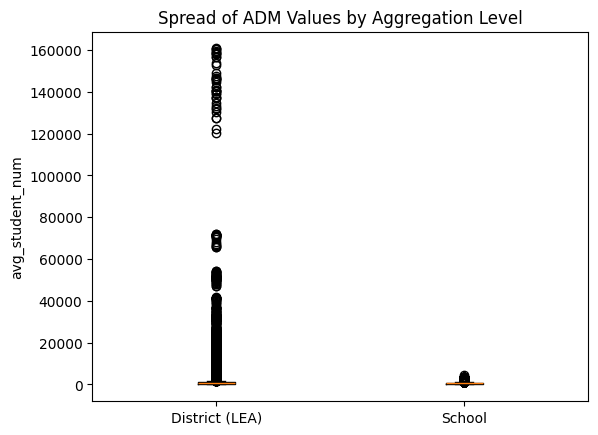

In [20]:
# Box plot of avg_student_num, split by level. State is left off -- with
# only one state total, a box plot needs more than one value to be meaningful.
plt.boxplot([district_level, school_level], tick_labels=["District (LEA)", "School"])
plt.ylabel("avg_student_num")
plt.title("Spread of ADM Values by Aggregation Level")
plt.show()

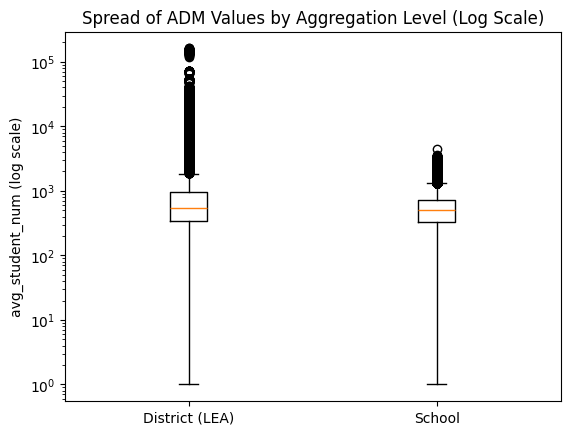

In [21]:
# Same box plot, but with a log-scaled y-axis. A log transform compresses
# the long right tail (Ch. 6, "Common Transforms"), so the box and whiskers
# should become visible again instead of disappearing under a wall of
# outlier dots.
#
# Log scale can't show 0, and we already found a few avg_student_num == 0
# rows earlier, so we drop those (5 rows total, out of 62,748) for this
# plot only.
district_positive = district_level[district_level > 0]
school_positive = school_level[school_level > 0]

plt.boxplot([district_positive, school_positive], tick_labels=["District (LEA)", "School"])
plt.yscale("log")
plt.ylabel("avg_student_num (log scale)")
plt.title("Spread of ADM Values by Aggregation Level (Log Scale)")
plt.show()

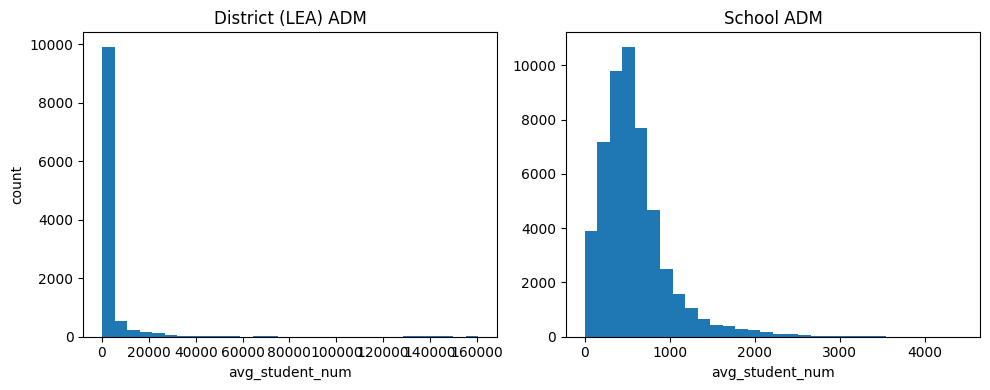

In [22]:
# Histograms of avg_student_num, split by level (Ch. 3's "Visualization in
# EDA" toolkit -- a histogram is the standard first tool for seeing a
# distribution's shape: skewness, peaks, and gaps are all visible at a glance).
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(district_level, bins=30)
axes[0].set_title("District (LEA) ADM")
axes[0].set_xlabel("avg_student_num")
axes[0].set_ylabel("count")

axes[1].hist(school_level, bins=30)
axes[1].set_title("School ADM")
axes[1].set_xlabel("avg_student_num")

plt.tight_layout()
plt.show()

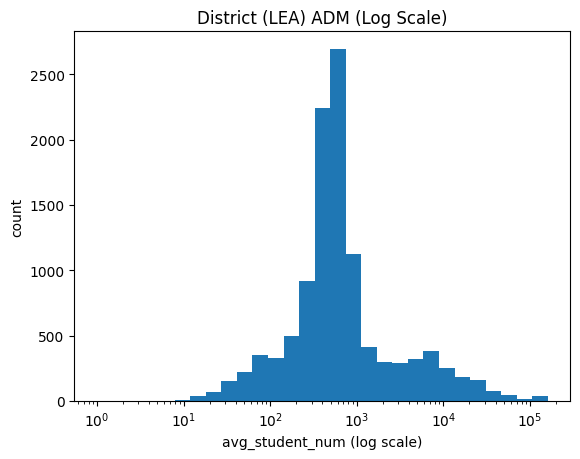

In [23]:
import numpy as np

# Log-x version of the district ADM histogram. A log-scaled histogram needs
# log-spaced bins, not evenly-spaced ones -- otherwise most bins would still
# be too wide near the low end to show any detail. Reuses district_positive
# from the log box plot cell above (log scale can't show the 0 values).
log_bins = np.logspace(np.log10(district_positive.min()), np.log10(district_positive.max()), 30)

plt.hist(district_positive, bins=log_bins)
plt.xscale("log")
plt.xlabel("avg_student_num (log scale)")
plt.ylabel("count")
plt.title("District (LEA) ADM (Log Scale)")
plt.show()

In [24]:
# Descriptive statistics
# - mean, median, mode -- central tendency
# - IQR, spread (std dev) -- how spread out the values are
# - skew -- which way the tail is long (positive = long right tail)
# - kurtosis -- "tailedness": how much more extreme-value-prone this
#   distribution is than a normal distribution would be
#
# mode() can return more than one value if there's a tie, so we just take
# the first one with .iloc[0].

stats_by_level = pd.DataFrame({
    "District (LEA)": {
        "mean": district_level.mean(),
        "median": district_level.median(),
        "mode": district_level.mode().iloc[0],
        "IQR": district_level.quantile(0.75) - district_level.quantile(0.25),
        "spread (std dev)": district_level.std(),
        "skew": district_level.skew(),
        "kurtosis": district_level.kurt(),
    },
    "School": {
        "mean": school_level.mean(),
        "median": school_level.median(),
        "mode": school_level.mode().iloc[0],
        "IQR": school_level.quantile(0.75) - school_level.quantile(0.25),
        "spread (std dev)": school_level.std(),
        "skew": school_level.skew(),
        "kurtosis": school_level.kurt(),
    },
})
stats_by_level.round(2)

,District (LEA),School
mean,2898.00,575.27
median,543.00,507.00
mode,475.00,511.00
IQR,603.00,394.00
spread (std dev),10618.96,384.65
skew,9.74,1.83
kurtosis,118.65,5.65


In [25]:
# The 8-dimension Data Quality Assessment (Ch. 6). One sentence each --
# some of these we can't fully answer yet, and that's noted rather than
# skipped.
dqa_summary = pd.DataFrame({
    "Dimension": [
        "Profiling",
        "Completeness",
        "Accuracy",
        "Consistency",
        "Integrity",
        "Lineage and Provenance",
        "Automated Testing",
        "Continuous Monitoring",
    ],
    "Assessment": [
        "Done in Section 3: 62,748 rows, 4 columns, one numeric column (avg_student_num).",
        "No true missing values. The 53,793 blank category_code cells are structural, not missing -- a blank marks a total row (see Section 4's category_code note). Some avg_student_num values are exactly 0, which may represent a different kind of missing.",
        f"Spot-checked one number (CHCCS 2025 district total, 11,065) against the board deck's reported figure and it matched exactly; broader accuracy is unverified.",
        "Single official release in one consistent format; no cross-source consistency problems found within this table.",
        f"agency_code follows a documented format (school / LEA / state codes); checked for duplicate (year, agency_code, category_code) rows and found {duplicate_count}.",
        "Fully documented: NC DPI bulk ZIP -> rcd_adm.xlsx extracted -> converted to CSV, tracked in data_sources/INDEX.md.",
        "None -- this is a one-time manual exploration, not a pipeline with validation rules.",
        "None -- a static snapshot downloaded once, not a live or refreshed feed.",
    ],
})
dqa_summary

,Dimension,Assessment
0,Profiling,"Done in Section 3: 62,748 rows, 4 columns, one..."
1,Completeness,"No true missing values. The 53,793 blank categ..."
2,Accuracy,Spot-checked one number (CHCCS 2025 district t...
3,Consistency,Single official release in one consistent form...
4,Integrity,agency_code follows a documented format (schoo...
5,Lineage and Provenance,Fully documented: NC DPI bulk ZIP -> rcd_adm.x...
6,Automated Testing,"None -- this is a one-time manual exploration,..."
7,Continuous Monitoring,"None -- a static snapshot downloaded once, not..."


### Observations from the Data Quality Check

- The file mixes three very different levels in one column -- state, district, and school -- so any stat or chart on `avg_student_num` is meaningless until you split by level first. The original describe() max of 1.5 million was the whole state sitting next to individual schools.
- District-level ADM is extremely skewed (skew ~9.7, kurtosis ~119) because NC's ~115 districts range from tiny charters to Wake County and CMS with 100,000+ students each. School-level is skewed too, but nowhere near as hard.
- The file itself looks clean -- no duplicates, almost no missing values, one number we checked matched CHCCS's reported figure. 

### Quality Check: LEA Population Crosswalk

Same kind of check as the rest of this section, applied to the new `data/lea_population_crosswalk.csv` file before trusting it in Section 5.

In [26]:
population_check = pd.read_csv("../data/lea_population_crosswalk.csv", dtype={"dpi_agency_code": str})

print("Duplicate (district, year) rows:", population_check.duplicated(subset=["dpi_agency_code", "year"]).sum())
print()
print("Missing values per column:")
print(population_check.isnull().sum())

Duplicate (district, year) rows: 0

Missing values per column:
dpi_agency_code    0
year               0
district_name      0
pop_total          0
pop_5_17           0
pov_5_17           0
dtype: int64


In [27]:
# Coverage check: does every year have the same set of districts?
years_per_district = population_check.groupby("dpi_agency_code")["year"].nunique()
print("Districts with all 6 years present:", (years_per_district == 6).sum())
print("Districts with fewer than 6 years:")
population_check[population_check["dpi_agency_code"].isin(years_per_district[years_per_district < 6].index)][["dpi_agency_code", "district_name", "year"]]

Districts with all 6 years present: 115
Districts with fewer than 6 years:


,dpi_agency_code,district_name,year
362,679LEA,Camp Lejeune Schools,2022
369,209LEA,Cherokee Central Schools,2022
387,269LEA,Fort Bragg Schools,2022
480,679LEA,Camp Lejeune Schools,2023
487,209LEA,Cherokee Central Schools,2023
505,269LEA,Fort Bragg Schools,2023
598,679LEA,Camp Lejeune Schools,2024
605,209LEA,Cherokee Central Schools,2024
623,269LEA,Fort Bragg Schools,2024


**Observation:** clean overall -- no duplicates, no missing values in any column. One coverage wrinkle: the crosswalk has 118 districts, not the 115 real LEAs we've been using elsewhere. The extra three (Cherokee Central Schools, Fort Bragg, Camp Lejeune -- the federal/tribal schools identified in Section 2) only have population data for 2022-2024, not the full 2019-2024 window, and they're not part of DPI's own ADM release at all. We'll need to exclude them when comparing to enrollment in Section 5.

## 5. Exploration

Section 4 said the data is clean. In this section we explore what it says

Three starting questions anchored our exploration. First, is CHCCS's enrollment decline unusual, or is every NC district seeing the same thing? That needs a comparison against all ~115 districts, not just CHCCS on its own. Second, is enrollment falling because fewer children live here, or because fewer of the children who live here enroll in CHCCS? That question can't be answered with DPI data alone, so for this question we pulled in the census data.

The third thing wasn't planned. Setting up an elementary-specific comparison surfaced a data quality / measurement trap in how "elementary enrollment" has to be constructed from this data



In [28]:
# Filter to district (LEA) rows only, keeping the blank-category_code rows.
#
# What category_code actually means here (verified in Section 4): for a
# district row, a BLANK category_code is the district's true total ADM --
# it equals the sum of that district's individual schools exactly. The rows
# tagged E/M/H/A/I/T are NOT a breakdown of that total; they're the AVERAGE
# ADM per school of that grade span. So blank is what we want, and the
# lettered rows must be excluded or we'd be mixing totals with averages.
adm_lea = adm[(adm["agency_code"].str.endswith("LEA")) & (adm["category_code"].isna())]


def pct_change_by_lea(df, value_col, start_year, end_year):
    """Percent change in value_col between start_year and end_year, per LEA.

    Assumes df already has exactly one row per (agency_code, year) -- any
    filtering (to a specific subgroup, category, etc.) needs to happen
    before calling this.
    """
    start_values = df[df["year"] == start_year].set_index("agency_code")[value_col]
    end_values = df[df["year"] == end_year].set_index("agency_code")[value_col]
    pct_change = (end_values - start_values) / start_values * 100
    return pct_change


enrollment_change_full_history = pct_change_by_lea(adm_lea, "avg_student_num", 2006, 2025)
print("LEAs with data in both 2006 and 2025:", enrollment_change_full_history.notna().sum())
print("CHCCS's enrollment change, 2006-2025:", round(enrollment_change_full_history["681LEA"], 1), "%")

LEAs with data in both 2006 and 2025: 115
CHCCS's enrollment change, 2006-2025: 0.8 %


In [29]:
# Where does CHCCS rank among all LEAs?
ranked = enrollment_change_full_history.dropna().sort_values()
chccs_rank = ranked.index.get_loc("681LEA") + 1  # +1 so rank 1 = biggest decline

print(f"CHCCS ranks {chccs_rank} out of {len(ranked)} LEAs, sorted from biggest decline to biggest growth.")
print()
print("Five-number summary of enrollment change across all LEAs:")
ranked.describe()

CHCCS ranks 90 out of 115 LEAs, sorted from biggest decline to biggest growth.

Five-number summary of enrollment change across all LEAs:


count    115.000000
mean     -11.382766
std       20.279310
min      -62.135604
25%      -23.634130
50%      -13.322034
75%       -0.060821
max       61.792709
Name: avg_student_num, dtype: float64

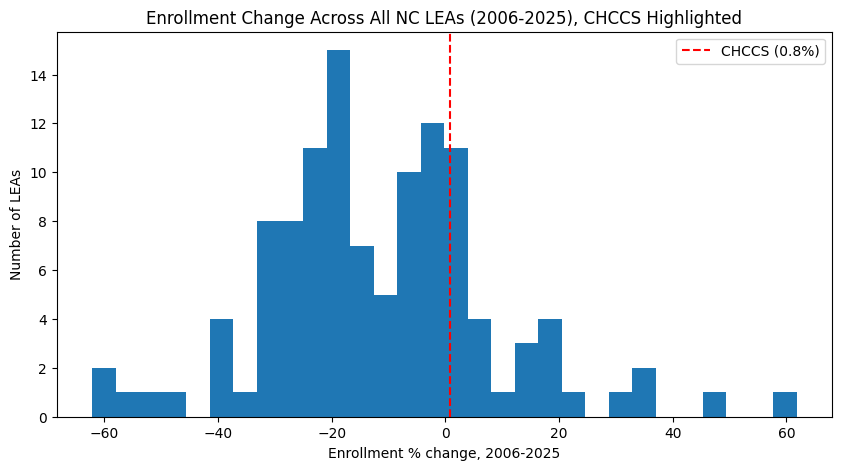

In [30]:
plt.figure(figsize=(10, 5))
plt.hist(ranked, bins=30)
plt.axvline(ranked["681LEA"], color="red", linestyle="--", label=f"CHCCS ({ranked['681LEA']:.1f}%)")
plt.xlabel("Enrollment % change, 2006-2025")
plt.ylabel("Number of LEAs")
plt.title("Enrollment Change Across All NC LEAs (2006-2025), CHCCS Highlighted")
plt.legend()
plt.show()

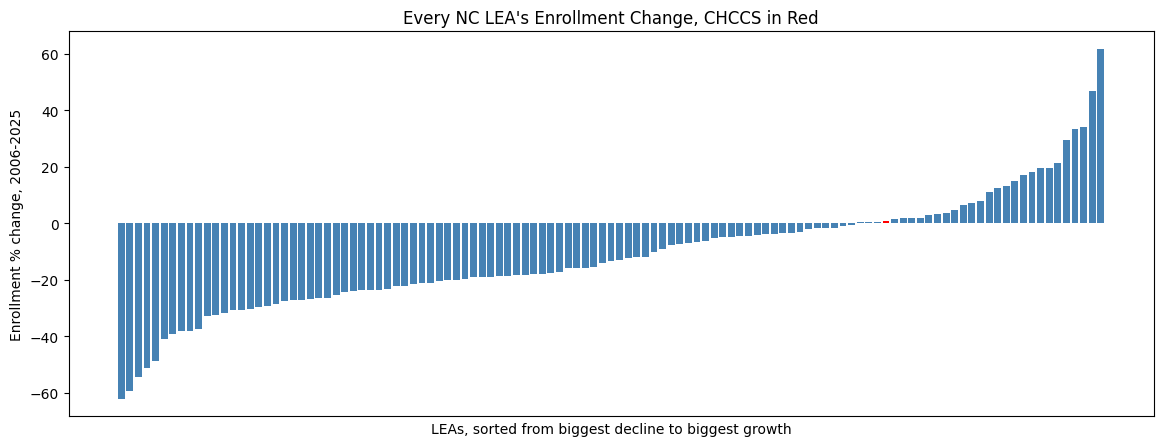

In [31]:
# Every LEA, sorted by enrollment change, CHCCS highlighted -- shows
# exactly where CHCCS sits relative to all ~115 other districts, not just
# which bucket of the histogram it falls in.
plt.figure(figsize=(14, 5))
colors = ["red" if lea == "681LEA" else "steelblue" for lea in ranked.index]
plt.bar(range(len(ranked)), ranked.values, color=colors)
plt.xlabel("LEAs, sorted from biggest decline to biggest growth")
plt.ylabel("Enrollment % change, 2006-2025")
plt.title("Every NC LEA's Enrollment Change, CHCCS in Red")
plt.xticks([])
plt.show()

CHCCS enrollment is roughly flat over 2006-2025. CHCCS grew for a decade, peaked in 2019, and has only been declining since (Section 4). Next we will take a deeper dive into the data since 2019

In [32]:
# Same ranking, but using the post-peak window (2019-2025) instead of the
# full history -- this is the window that actually matches the decline the
# board deck is describing.
recent_change = pct_change_by_lea(adm_lea, "avg_student_num", 2019, 2025)
recent_ranked = recent_change.dropna().sort_values()
chccs_recent_rank = recent_ranked.index.get_loc("681LEA") + 1

print(f"CHCCS's enrollment change, 2019-2025: {recent_ranked['681LEA']:.1f}%")
print(f"CHCCS ranks {chccs_recent_rank} out of {len(recent_ranked)} LEAs (1 = biggest decline).")
print()
print("Five-number summary, 2019-2025:")
recent_ranked.describe()

CHCCS's enrollment change, 2019-2025: -10.3%
CHCCS ranks 35 out of 115 LEAs (1 = biggest decline).

Five-number summary, 2019-2025:


count    115.000000
mean      -6.757721
std        8.546717
min      -31.811024
25%      -11.335000
50%       -7.047660
75%       -2.430442
max       28.901170
Name: avg_student_num, dtype: float64

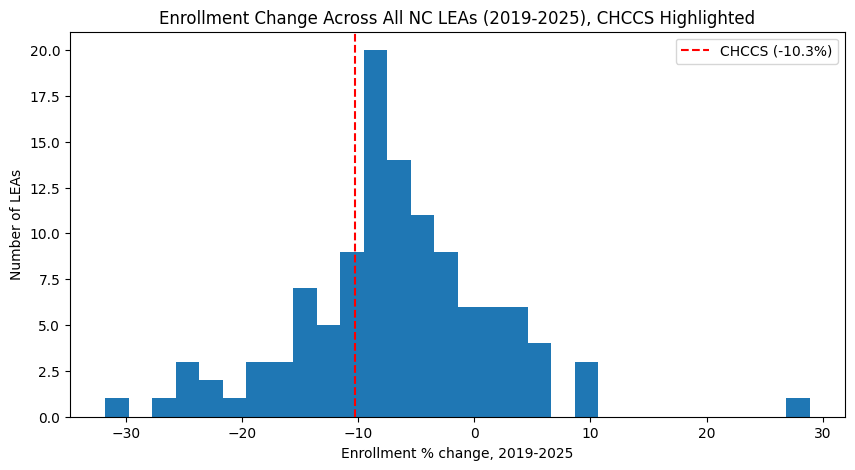

In [33]:
plt.figure(figsize=(10, 5))
plt.hist(recent_ranked, bins=30)
plt.axvline(recent_ranked["681LEA"], color="red", linestyle="--", label=f"CHCCS ({recent_ranked['681LEA']:.1f}%)")
plt.xlabel("Enrollment % change, 2019-2025")
plt.ylabel("Number of LEAs")
plt.title("Enrollment Change Across All NC LEAs (2019-2025), CHCCS Highlighted")
plt.legend()
plt.show()

### Observations from Section 5

- Window choice matters a lot here. Over the full 2006-2025 history, CHCCS looks flat (+0.8%, rank 90 out of 115 -- among the least-declining districts in the state). Over 2019-2025, the window that actually matches the board's own framing, CHCCS is down 10.3% and ranks 35th out of 115 for decline -- worse than the median NC district (-7.0%), though far from the most extreme (-31.8%).
- So: CHCCS's recent decline is real, and it's sharper than a typical NC district's, but it's not unique to CHCCS or even close to the state's worst case. A meaningful share of NC districts are losing students faster.

### Enrollment vs. School-Age Population

Everything above compares CHCCS's enrollment to *other districts'* enrollment. That doesn't say *why* enrollment is falling -- it could be because fewer school-age kids live in the district, or because a shrinking share of the kids who do live there are enrolling in CHCCS specifically (charter, private, homeschool). To start separating those two explanations, we bring in Census population estimates (ages 5-17) for every NC district, crosswalked to DPI's codes by `src/build_lea_population_crosswalk.py` (see Section 2).

One window note: Census's data (SAIPE) only goes through 2024, one year short of the 2025 ADM data we've been using elsewhere. So this comparison uses 2019-2024, not 2019-2025 -- close to, but not exactly, the same window as the rest of this section.

In [34]:
# Load the crosswalked population data and rename its ID column to match
# the "agency_code" name pct_change_by_lea() expects, so we can reuse the
# same function from earlier in this section instead of writing a new one.
population = pd.read_csv("../data/lea_population_crosswalk.csv", dtype={"dpi_agency_code": str})
population = population.rename(columns={"dpi_agency_code": "agency_code"})

pop_change = pct_change_by_lea(population, "pop_5_17", 2019, 2024)
enrollment_change_19_24 = pct_change_by_lea(adm_lea, "avg_student_num", 2019, 2024)

comparison = pd.DataFrame({
    "pop_5_17_pct_change": pop_change,
    "enrollment_pct_change": enrollment_change_19_24,
}).dropna()

print("Districts with both a population and enrollment figure:", len(comparison))
print()
print("Correlation between the two:", round(comparison["pop_5_17_pct_change"].corr(comparison["enrollment_pct_change"]), 2))
print()
print("CHCCS:")
comparison.loc["681LEA"]

Districts with both a population and enrollment figure: 115

Correlation between the two: 0.58

CHCCS:


pop_5_17_pct_change     -5.786452
enrollment_pct_change   -8.666396
Name: 681LEA, dtype: float64

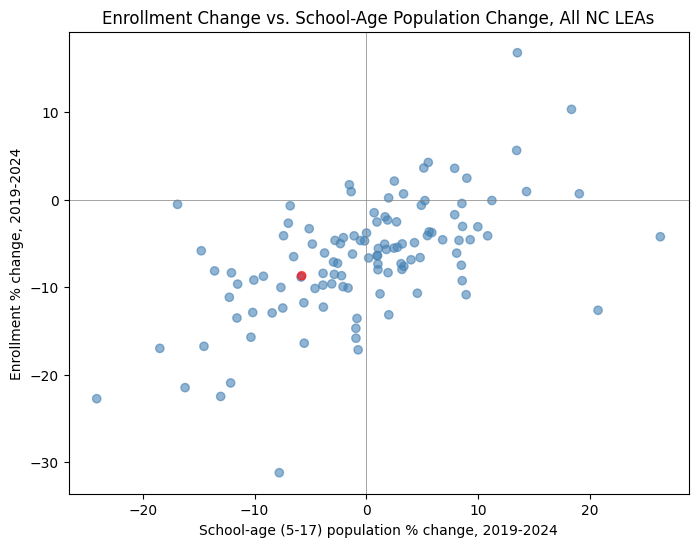

In [35]:
plt.figure(figsize=(8, 6))
colors = ["red" if lea == "681LEA" else "steelblue" for lea in comparison.index]
plt.scatter(comparison["pop_5_17_pct_change"], comparison["enrollment_pct_change"], c=colors, alpha=0.6)
plt.xlabel("School-age (5-17) population % change, 2019-2024")
plt.ylabel("Enrollment % change, 2019-2024")
plt.title("Enrollment Change vs. School-Age Population Change, All NC LEAs")
plt.axhline(0, color="gray", linewidth=0.5)
plt.axvline(0, color="gray", linewidth=0.5)
plt.show()

**Observation:** across all 115 districts, enrollment change and school-age population change move together with a correlation of about 0.58 -- a real relationship.

For CHCCS specifically: enrollment fell 8.7% while the 5-17 population fell 5.8% over the same 2019-2024 window. So some of CHCCS's decline lines up with fewer school-age kids living in the district, and some doesn't -- there's a gap left over that population alone doesn't explain. That gap is where school-choice questions (charter, private, homeschool) would need to come in, which is beyond what this dataset can answer on its own.

### A Data Quality Trap: "Elementary Enrollment" Isn't in the Data

We want to look at elementary enrollment specifically, since that's where the closure decision is happening. But DPI publishes **no grade-level enrollment table** -- `rcd_adm` gives a total per school, not a breakdown by grade. So elementary enrollment has to be constructed: take the schools DPI labels elementary (`category_code == "E"`) and sum their ADM.

That construction contains a trap. Not every elementary-aged child attends a school labeled `E`. Districts also run K-8 schools (`I`) and K-12 schools (`A`), and the elementary-aged children in those buildings are **invisible** to an `E`-only sum. The check below shows how widespread that is.

Why it matters for what we're doing: this undercount is mostly harmless when measuring *change over time*, because if a district's mix of school types stays stable, both endpoints undercount by roughly the same proportion and the percentage change survives. It becomes a real problem only if a district reconfigures its grade structure mid-period -- converting K-5 schools into K-8 schools, say -- because then the `E` sum moves for reasons that have nothing to do with enrollment.

It's worth being explicit that this is a constructed measure with a known blind spot, rather than treating "elementary enrollment" as something the data handed us.

In [36]:
# How many elementary-aged students are invisible to an "E-only" sum?
# rcd_location tells us each school's grade-span category:
#   E = elementary only      I = elementary + middle (K-8)
#   M = middle               A = elementary + middle + high (K-12)
#   H = high school          T = middle + high
location = pd.read_csv("../data_sources/nc_dpi_rcd_location_2024-25.csv",
                       dtype={"agency_code": str, "lea_code": str}, low_memory=False)

school_rows = adm[
    ~adm["agency_code"].str.endswith("LEA")
    & (adm["agency_code"] != "NC-SEA")
    & adm["category_code"].isna()
]
spans = location[["year", "agency_code", "category_code", "lea_code"]].rename(columns={"category_code": "span"})
schools_with_spans = school_rows.merge(spans, on=["year", "agency_code"], how="left")

print("NC schools by grade-span category (2024):")
print(schools_with_spans[schools_with_spans["year"] == 2024]["span"].value_counts().to_string())

NC schools by grade-span category (2024):
span
E    1309
H     528
M     470
I     183
A     129
T      82


Districts with at least one K-8 or K-12 school: 55 of 116
Districts where those schools hold >10% of students: 18

Most affected districts (% of ADM in K-8/K-12 schools):
lea_code
480LEA    93.3
CH        88.0
030LEA    69.3
950LEA    66.4
500LEA    61.6

CHCCS: 0.00%


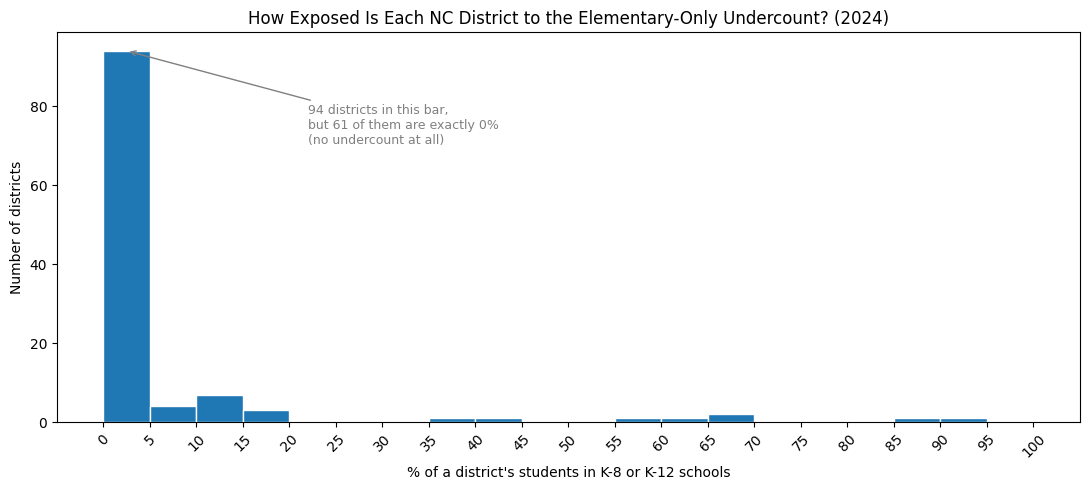

Exactly 0%:            61 districts -- elementary sum is exact
Between 0% and 5%:     33 districts -- minor undercount
5% or more:            22 districts -- meaningful undercount
20% or more:           8 districts -- elementary sum is unreliable


In [37]:
# For each district, what share of its students sit in K-8 or K-12 schools
# (and would therefore be missed by an elementary-only sum)?
year_2024 = schools_with_spans[schools_with_spans["year"] == 2024]

district_totals = year_2024.groupby("lea_code")["avg_student_num"].sum()
combined_totals = year_2024[year_2024["span"].isin(["I", "A"])].groupby("lea_code")["avg_student_num"].sum()
combined_share = (combined_totals / district_totals * 100).reindex(district_totals.index).fillna(0)

print(f"Districts with at least one K-8 or K-12 school: {(combined_share > 0).sum()} of {len(combined_share)}")
print(f"Districts where those schools hold >10% of students: {(combined_share > 10).sum()}")
print()
print("Most affected districts (% of ADM in K-8/K-12 schools):")
print(combined_share.sort_values(ascending=False).head(5).round(1).to_string())
print()
print(f"CHCCS: {combined_share['681LEA']:.2f}%")

# Visualize the problem space: how many districts sit at each level of
# exposure? Buckets are 5 percentage points wide.
bucket_edges = np.arange(0, 105, 5)

plt.figure(figsize=(11, 5))
plt.hist(combined_share, bins=bucket_edges, edgecolor="white")
plt.xlabel("% of a district's students in K-8 or K-12 schools")
plt.ylabel("Number of districts")
plt.title("How Exposed Is Each NC District to the Elementary-Only Undercount? (2024)")
plt.xticks(bucket_edges, rotation=45)

# The first bar is misleading on its own -- most of it is districts at
# exactly 0%, which have no undercount at all. Call that out on the chart.
exactly_zero = (combined_share == 0).sum()
first_bucket = ((combined_share >= 0) & (combined_share < 5)).sum()
plt.annotate(
    f"{first_bucket} districts in this bar,\nbut {exactly_zero} of them are exactly 0%\n(no undercount at all)",
    xy=(2.5, first_bucket), xytext=(22, first_bucket * 0.75),
    arrowprops=dict(arrowstyle="->", color="gray"), fontsize=9, color="gray",
)

plt.tight_layout()
plt.show()

print(f"Exactly 0%:            {exactly_zero} districts -- elementary sum is exact")
print(f"Between 0% and 5%:     {first_bucket - exactly_zero} districts -- minor undercount")
print(f"5% or more:            {(combined_share >= 5).sum()} districts -- meaningful undercount")
print(f"20% or more:           {(combined_share >= 20).sum()} districts -- elementary sum is unreliable")

**Observation:** roughly half of NC districts (55 of 116) run at least one K-8 or K-12 school, so an elementary-only sum undercounts their elementary enrollment. For most it's a small slice, but the extremes are severe -- one district holds 93% of its students in combined-grade schools, and eight are above 20%. For those districts, "elementary enrollment" as constructed here is close to meaningless.

CHCCS is at the opposite end: 0% in 2024. Its elementary-aged students are all in standalone `E` schools, so its figure is clean. (It had a single K-12 school in 2019 -- the UNC Hospital School, all of 2 students -- which is why its share is 0.016% rather than exactly zero that year.)

This shapes how the statewide comparison gets done in Section 7: rather than pick one treatment of these districts and hope it doesn't matter, we run the comparison several ways and check whether the conclusion moves.

## 6. Preprocessing (Part 2 — see also Sections 2-4 for the Census/DPI crosswalk)

Section 5 raised a question it couldn't answer: if enrollment is falling faster than the school-age population, what else moves with it? Answering that means testing other variables against enrollment change, and to compare variables they all have to be shaped the same way — one row per district, one number per variable.

That's the work here. Four more DPI tables get pulled in (% economically disadvantaged, chronic absenteeism, per-pupil expenditure, Pre-K enrollment), each filtered down to district-level totals and reduced to a single percent change per district, then merged into one table keyed by district code.

Two decisions worth stating up front. The comparison window is 2019-2025, set by per-pupil expenditure, which is the latest-starting of the four tables — everything has to share a window or the comparison isn't fair. And the merged table gets restricted to the 115 real districts, because some "LEA"-suffixed codes in these tables aren't school districts at all.

**Not all of this project's preprocessing happens in this section.** The hardest preprocessing problem in the project was joining Census population data to NC DPI enrollment data, which can't be done directly: DPI identifies CHCCS as `681LEA`, Census identifies it as NCES ID `3700720`, and neither can be derived from the other. Bridging them required a third dataset (the NCES district directory) as a translation layer.

Because that's a self-contained data-engineering job rather than analysis, it lives in its own script, `src/build_lea_population_crosswalk.py`, and is covered across three earlier sections: **Section 2** explains what it does and why it's needed, **Section 3** loads its output, and **Section 4** quality-checks that output before anything depends on it. This section handles the remaining preprocessing — reshaping the DPI tables themselves.


In [38]:
# Load the four additional tables. agency_code needs to stay a string (it
# has leading zeros and suffixes like "LEA"), so we tell pandas that
# explicitly instead of letting it guess the type.
eds = pd.read_csv("../data_sources/nc_dpi_rcd_acc_eds_2024-25.csv", dtype={"agency_code": str})
chronic_absent = pd.read_csv("../data_sources/nc_dpi_rcd_chronic_absent_2024-25.csv", dtype={"agency_code": str})
funds2 = pd.read_csv("../data_sources/nc_dpi_rcd_funds2_2024-25.csv", dtype={"agency_code": str})
pk_enroll = pd.read_csv("../data_sources/nc_dpi_rcd_pk_enroll_2024-25.csv", dtype={"agency_code": str})

print("eds:", eds.shape)
print("chronic_absent:", chronic_absent.shape)
print("funds2:", funds2.shape)
print("pk_enroll:", pk_enroll.shape)

eds: (25222, 4)
chronic_absent: (204889, 7)
funds2: (146791, 13)
pk_enroll: (81928, 7)


In [39]:
# Filter each table down to one row per (agency_code, year): district
# level only, and for the tables that have subgroups or categories, just
# the overall total (not broken out by race, gender, or spending category).
eds_lea = eds[eds["agency_code"].str.endswith("LEA")]
chronic_absent_lea = chronic_absent[(chronic_absent["agency_code"].str.endswith("LEA")) & (chronic_absent["subgroup"] == "ALL")]
funds2_lea = funds2[(funds2["agency_code"].str.endswith("LEA")) & (funds2["expenditure_category"] == "TOTAL")]
pk_enroll_lea = pk_enroll[(pk_enroll["agency_code"].str.endswith("LEA")) & (pk_enroll["subgroup"] == "ALL")]

print("eds_lea:", eds_lea.shape)
print("chronic_absent_lea:", chronic_absent_lea.shape)
print("funds2_lea:", funds2_lea.shape)
print("pk_enroll_lea:", pk_enroll_lea.shape)

eds_lea: (1036, 4)
chronic_absent_lea: (1142, 7)
funds2_lea: (808, 13)
pk_enroll_lea: (886, 7)


In [40]:
# funds2 doesn't start until 2019 -- the latest starting point of the four
# new tables -- so 2019 is the common start year for comparing all five
# variables on equal footing. (Section 5's ADM-only comparison used the
# full 2006-2025 history since it wasn't being compared to anything else;
# here, everything needs the same window to be a fair comparison.)
START_YEAR = 2019
END_YEAR = 2025

enrollment_change = pct_change_by_lea(adm_lea, "avg_student_num", START_YEAR, END_YEAR)
eds_change = pct_change_by_lea(eds_lea, "pct_eds", START_YEAR, END_YEAR)
chronic_absent_change = pct_change_by_lea(chronic_absent_lea, "pct", START_YEAR, END_YEAR)
funds_change = pct_change_by_lea(funds2_lea, "total_ppe", START_YEAR, END_YEAR)
pk_enroll_change = pct_change_by_lea(pk_enroll_lea, "count_masked", START_YEAR, END_YEAR)

print("LEAs with a valid enrollment change:", enrollment_change.notna().sum())
print("LEAs with a valid % economically disadvantaged change:", eds_change.notna().sum())
print("LEAs with a valid chronic absenteeism change:", chronic_absent_change.notna().sum())
print("LEAs with a valid per-pupil expenditure change:", funds_change.notna().sum())
print("LEAs with a valid Pre-K enrollment change:", pk_enroll_change.notna().sum())

LEAs with a valid enrollment change: 115
LEAs with a valid % economically disadvantaged change: 115
LEAs with a valid chronic absenteeism change: 115
LEAs with a valid per-pupil expenditure change: 115
LEAs with a valid Pre-K enrollment change: 107


In [41]:
# Merge all five into one table, one row per LEA. Some agency_codes ending
# in "LEA" aren't real school districts (special-purpose codes, per the
# masking rules we read in Section 2) -- restrict to rows with a real
# enrollment_pct_change, since that's every table's anchor variable and we
# know from Section 5 there are exactly 115 real LEAs in it.
trend_table = pd.DataFrame({
    "enrollment_pct_change": enrollment_change,
    "eds_pct_change": eds_change,
    "chronic_absent_pct_change": chronic_absent_change,
    "ppe_pct_change": funds_change,
    "pk_enroll_pct_change": pk_enroll_change,
})
trend_table = trend_table.dropna(subset=["enrollment_pct_change"])

print("Shape after restricting to real LEAs:", trend_table.shape)
print("Of those, LEAs with all five variables present:", trend_table.dropna().shape[0])
trend_table.head()

Shape after restricting to real LEAs: (115, 5)
Of those, LEAs with all five variables present: 105


,enrollment_pct_change,eds_pct_change,chronic_absent_pct_change,ppe_pct_change,pk_enroll_pct_change
agency_code,,,,,
010LEA,-2.476835,17.450980,34.269143,25.223588,-16.422287
020LEA,-13.607990,12.471132,99.913574,29.362833,35.211268
030LEA,-6.607275,-4.707792,-13.763019,28.842254,3.750000
040LEA,-9.407338,35.523979,31.588500,36.661272,NaN
050LEA,-14.506380,-2.966841,-6.731101,34.660260,-1.408451


In [42]:
# CHCCS's own row in the merged table
trend_table.loc["681LEA"]

enrollment_pct_change       -10.295906
eds_pct_change               18.217054
chronic_absent_pct_change    84.461914
ppe_pct_change               34.442452
pk_enroll_pct_change         75.728155
Name: 681LEA, dtype: float64

### Observations from Section 6

- Merging five tables down to one row per LEA worked cleanly for enrollment, % economically disadvantaged, chronic absenteeism, and per-pupil expenditure -- every one of the 115 real LEAs has a value for those. Pre-K enrollment is the exception: a handful of LEAs are missing it, most likely due to the masking rule from Section 2 (small counts get suppressed).
- 105 of 115 real LEAs have all five variables present -- good enough to move forward with, though it means Section 7's correlations are based on a slightly smaller, probably somewhat larger-district-skewed set of LEAs, not literally every district in the state.

## 7. Feature Engineering

This section has two halves, and the first one mostly failed.

The first half is the exploratory pass set up in Section 6: take four candidate variables and see which move with enrollment change across districts. Three found nothing. The one that did find something turned out to be measuring itself.

The second half is the feature that works — capture rate, the share of a district's resident school-age children who enroll in its schools. That's the one that splits the enrollment decline into a part explained by demographics and a part that isn't.

**What came out of it:**

| Variable | Correlation with enrollment change |
|---|---|
| Per-pupil expenditure | -0.62 |
| % economically disadvantaged | -0.16 |
| Pre-K enrollment | 0.04 |
| Chronic absenteeism | -0.02 |

Per-pupil expenditure stands out, but probably not for an interesting reason: PPE's denominator *is* enrollment (total spending / ADM), so a district that loses students while its fixed costs stay flat will mechanically show rising per-pupil spending, no external driver required. This is close to definitional, not a discovery -- though it does line up with the board deck's own financial framing from Section 4.

The other three are weak to nonexistent. Notably, Pre-K enrollment change -- the "obvious" leading indicator -- shows essentially no relationship with overall enrollment change across LEAs.

**Note on what didn't correlate.** The four variables tested below were an honest exploratory pass, and three of them found nothing. They're kept in the notebook rather than deleted, because the absence of a relationship is itself a finding -- it's what pushed this analysis toward population data instead. See the capture-rate work further down for the feature that did carry the story.


In [43]:
# Correlation of each variable's change with enrollment change, across all
# LEAs that have both values present. pandas' .corr() handles this pairwise
# automatically -- for each pair of columns, it only uses the rows where
# both have a value.
correlations = trend_table.corr()["enrollment_pct_change"].drop("enrollment_pct_change")

# Sort by strength of relationship (positive or negative), strongest first.
correlations_ranked = correlations.reindex(correlations.abs().sort_values(ascending=False).index)
correlations_ranked

ppe_pct_change              -0.622028
eds_pct_change              -0.159719
pk_enroll_pct_change         0.043224
chronic_absent_pct_change   -0.021932
Name: enrollment_pct_change, dtype: float64

### The Feature That Works: Capture Rate

The four variables above were the exploratory pass, and they mostly came up empty. The feature below is the one that carries the story.

**Capture rate = enrollment / school-age population** -- the share of the district's resident 5-17 year olds who are enrolled in its schools. Unlike per-pupil expenditure, this isn't circular: population is measured independently of enrollment, so a relationship between them is informative rather than definitional.

What it lets us do is split the enrollment decline into two parts: the share explained by there simply being fewer children in the district, and the share left over, which is children who live here but enroll somewhere else (charter, private, homeschool, or leaving).

In [44]:
# Build the four nested layers for CHCCS. Elementary enrollment has to be
# assembled from school-level ADM, because DPI publishes no grade-level
# enrollment table -- rcd_location tells us which schools are elementary.
location = pd.read_csv("../data_sources/nc_dpi_rcd_location_2024-25.csv",
                       dtype={"agency_code": str, "lea_code": str}, low_memory=False)

school_adm = adm[
    ~adm["agency_code"].str.endswith("LEA")
    & (adm["agency_code"] != "NC-SEA")
    & adm["category_code"].isna()
]
school_spans = location[["year", "agency_code", "category_code", "lea_code"]].rename(
    columns={"category_code": "span"}
)
school_adm = school_adm.merge(school_spans, on=["year", "agency_code"], how="left")

# Elementary ADM per district-year, plus how many elementary schools it has
elementary = (
    school_adm[school_adm["span"] == "E"]
    .groupby(["year", "lea_code"])
    .agg(elem_adm=("avg_student_num", "sum"), n_elem_schools=("agency_code", "nunique"))
    .reset_index()
)

district_adm = adm_lea[["year", "agency_code", "avg_student_num"]].rename(
    columns={"avg_student_num": "total_adm", "agency_code": "lea_code"}
)
pop_layers = population.rename(columns={"agency_code": "lea_code"})[["year", "lea_code", "pop_total", "pop_5_17"]]

all_layers = district_adm.merge(pop_layers, on=["year", "lea_code"]).merge(
    elementary, on=["year", "lea_code"], how="left"
)

chccs_layers = all_layers[all_layers["lea_code"] == "681LEA"].set_index("year").sort_index()
chccs_layers[["pop_total", "pop_5_17", "total_adm", "elem_adm", "n_elem_schools"]].loc[2019:2024]

,pop_total,pop_5_17,total_adm,elem_adm,n_elem_schools
year,,,,,
2019,93239,13065,12335,5488.0,11.0
2020,93625,13120,12270,5356.0,11.0
2021,91444,12678,11645,4886.0,11.0
2022,92423,12421,11425,4742.0,11.0
2023,92514,12495,11371,4657.0,11.0
2024,93897,12309,11266,4583.0,11.0


In [45]:
# The four layers as percent change, 2019-2024.
start, end = chccs_layers.loc[2019], chccs_layers.loc[2024]

for label, column in [
    ("Total population", "pop_total"),
    ("School-age population (5-17)", "pop_5_17"),
    ("K-12 enrollment (ADM)", "total_adm"),
    ("Elementary enrollment", "elem_adm"),
]:
    change = (end[column] / start[column] - 1) * 100
    print(f"{label:30s} {start[column]:>8,.0f} -> {end[column]:>8,.0f}   {change:+6.1f}%")

Total population                 93,239 ->   93,897     +0.7%
School-age population (5-17)     13,065 ->   12,309     -5.8%
K-12 enrollment (ADM)            12,335 ->   11,266     -8.7%
Elementary enrollment             5,488 ->    4,583    -16.5%


In [46]:
# Capture rate, and the decomposition: how much of the enrollment decline
# does the shrinking school-age population actually explain?
chccs_layers["capture_rate"] = chccs_layers["total_adm"] / chccs_layers["pop_5_17"]
print("Capture rate by year:")
print(chccs_layers["capture_rate"].loc[2019:2024].round(4).to_string())
print()

capture_2019 = chccs_layers.loc[2019, "capture_rate"]
# What enrollment would 2024 have had, if the capture rate had held at its 2019 level?
expected_2024 = chccs_layers.loc[2024, "pop_5_17"] * capture_2019
actual_2024 = chccs_layers.loc[2024, "total_adm"]
total_decline = actual_2024 - chccs_layers.loc[2019, "total_adm"]

print(f"Actual enrollment decline, 2019-2024:      {total_decline:>7,.0f} students")
print(f"  explained by fewer school-age children:  {expected_2024 - chccs_layers.loc[2019, 'total_adm']:>7,.0f} students ({(expected_2024 - chccs_layers.loc[2019, 'total_adm'])/total_decline*100:.0f}%)")
print(f"  explained by a falling capture rate:     {actual_2024 - expected_2024:>7,.0f} students ({(actual_2024 - expected_2024)/total_decline*100:.0f}%)")

Capture rate by year:
year
2019    0.9441
2020    0.9352
2021    0.9185
2022    0.9198
2023    0.9100
2024    0.9153

Actual enrollment decline, 2019-2024:       -1,069 students
  explained by fewer school-age children:     -714 students (67%)
  explained by a falling capture rate:        -355 students (33%)


In [47]:
# Is CHCCS's elementary decline unusual? Compare against every district that
# has elementary enrollment in both years.
#
# Note on a guard we deliberately did NOT apply: it's tempting to exclude
# districts that opened or closed an elementary school. That would be wrong.
# This is a SUM across a district's elementary schools -- if a district opens
# a 12th elementary school, those students came from the existing 11, so the
# district total barely moves. Filtering on school count would throw away
# districts for no reason.
#
# The real measurement issue is different, and handled in the next cell.
elem_wide = elementary[elementary["year"].isin([2019, 2024])].pivot(
    index="lea_code", columns="year", values="elem_adm"
).dropna()

elementary_change = (elem_wide[2024] / elem_wide[2019] - 1) * 100

print(f"Districts with elementary enrollment in both years: {len(elementary_change)}")
print(f"CHCCS elementary change: {elementary_change['681LEA']:.1f}%")
print(f"Median district:         {elementary_change.median():.1f}%")
print(f"CHCCS rank (1 = steepest decline): {int(elementary_change.rank()['681LEA'])} of {len(elementary_change)}")
print()
print("CHCCS elementary schools stayed at", int(chccs_layers.loc[2024, "n_elem_schools"]),
      "the whole time, while average school size fell from",
      f"{chccs_layers.loc[2019, 'elem_adm']/chccs_layers.loc[2019, 'n_elem_schools']:.0f}",
      "to", f"{chccs_layers.loc[2024, 'elem_adm']/chccs_layers.loc[2024, 'n_elem_schools']:.0f}", "students.")

Districts with elementary enrollment in both years: 113
CHCCS elementary change: -16.5%
Median district:         -7.3%
CHCCS rank (1 = steepest decline): 17 of 113

CHCCS elementary schools stayed at 11 the whole time, while average school size fell from 499 to 417 students.


**The real measurement issue: combined-grade schools.** "Elementary enrollment" above is the sum of schools DPI categorizes as `E` (elementary only). But some districts educate elementary-aged children in K-8 (`I`) or K-12 (`A`) schools, and those children are invisible to an `E`-only sum. About half of NC districts have at least one such school.

That's fine for comparing *change over time* as long as a district's mix stays stable -- both endpoints undercount by roughly the same proportion, so the percentage change still holds. It breaks only if a district *reconfigures* its grade structure mid-period. So rather than guess, the check below re-runs the comparison under several treatments to see whether the conclusion actually depends on it.

In [48]:
# Sensitivity check: does CHCCS's position depend on how we handle districts
# with K-8/K-12 schools? Recompute under several treatments and compare.
def combined_school_share(year):
    """% of a district's ADM sitting in K-8 or K-12 schools that year."""
    rows = school_adm[school_adm["year"] == year]
    district_total = rows.groupby("lea_code")["avg_student_num"].sum()
    combined = rows[rows["span"].isin(["I", "A"])].groupby("lea_code")["avg_student_num"].sum()
    return (combined / district_total * 100).reindex(district_total.index).fillna(0)

share_2019, share_2024 = combined_school_share(2019), combined_school_share(2024)
shift = (share_2024 - share_2019).abs()

treatments = {
    "All districts": elementary_change.index,
    "Combined-school share <1% both years": elementary_change.index[
        (share_2019.reindex(elementary_change.index) < 1) & (share_2024.reindex(elementary_change.index) < 1)],
    "Grade-structure shift <1 pct point": elementary_change.index[
        shift.reindex(elementary_change.index) < 1],
}

for name, keep in treatments.items():
    subset = elementary_change.loc[elementary_change.index.isin(keep)]
    rank = int(subset.rank()["681LEA"])
    pctile = subset.rank(pct=True)["681LEA"] * 100
    print(f"{name:38s} n={len(subset):3d}  median={subset.median():6.1f}%  CHCCS rank {rank:3d} ({pctile:.0f}th pctile)")

print()
print(f"CHCCS's own combined-school share: {share_2019['681LEA']:.3f}% (2019) -> {share_2024['681LEA']:.3f}% (2024),")
print("so its elementary figure is essentially unaffected either way.")

All districts                          n=113  median=  -7.3%  CHCCS rank  17 (15th pctile)
Combined-school share <1% both years   n= 66  median=  -8.0%  CHCCS rank  11 (17th pctile)
Grade-structure shift <1 pct point     n= 84  median=  -7.9%  CHCCS rank  13 (15th pctile)

CHCCS's own combined-school share: 0.016% (2019) -> 0.000% (2024),
so its elementary figure is essentially unaffected either way.


## 8. Synthesis and Visualizations

Everything up to here was exploration. This section states what the data says.

The finding is a comparison between four numbers that are usually reported one at a time: the district's total population, its school-age population, its K-12 enrollment, and its elementary enrollment. Read individually, each supports a different story. Read together, they show something the board's own materials never present.


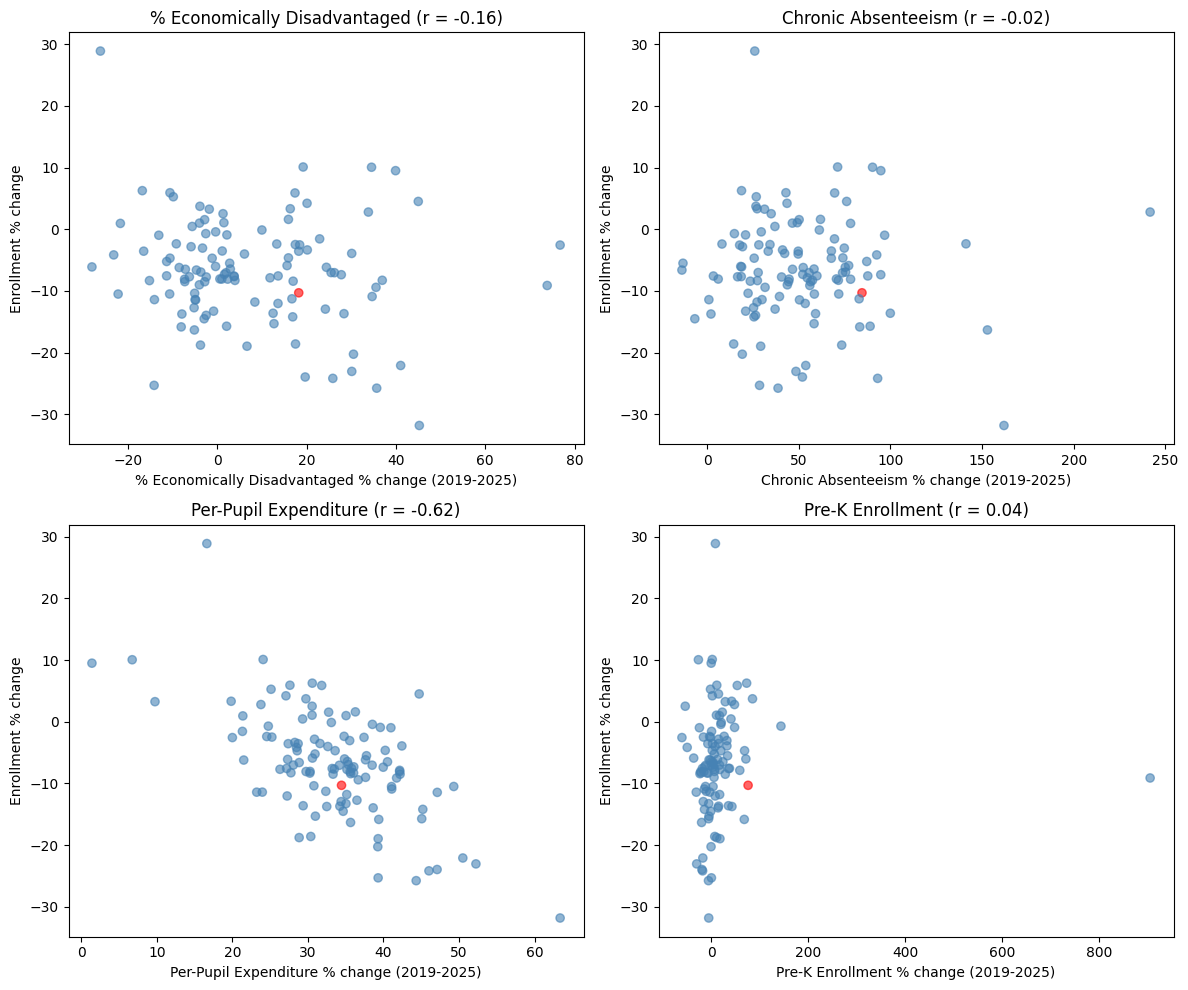

In [49]:
# One scatter plot per candidate variable vs. enrollment change, CHCCS
# highlighted in red. Same shape as the Section 5 plot, just with a second
# variable on the x-axis now instead of just looking at enrollment alone.
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

variable_pairs = [
    ("eds_pct_change", "% Economically Disadvantaged", axes[0, 0]),
    ("chronic_absent_pct_change", "Chronic Absenteeism", axes[0, 1]),
    ("ppe_pct_change", "Per-Pupil Expenditure", axes[1, 0]),
    ("pk_enroll_pct_change", "Pre-K Enrollment", axes[1, 1]),
]

for col, label, ax in variable_pairs:
    plot_data = trend_table[[col, "enrollment_pct_change"]].dropna()
    colors = ["red" if lea == "681LEA" else "steelblue" for lea in plot_data.index]
    ax.scatter(plot_data[col], plot_data["enrollment_pct_change"], c=colors, alpha=0.6)
    ax.set_xlabel(f"{label} % change ({START_YEAR}-{END_YEAR})")
    ax.set_ylabel("Enrollment % change")
    ax.set_title(f"{label} (r = {correlations[col]:.2f})")

plt.tight_layout()
plt.show()

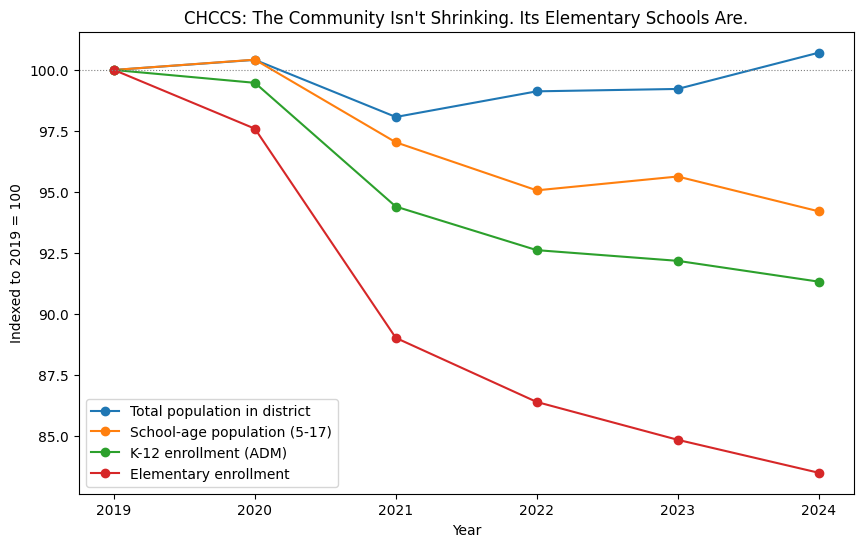

In [50]:
# The story in one chart: four nested layers, all indexed to 2019 = 100 so
# they can be compared on the same scale despite very different sizes.
# Select just the four numeric layers -- chccs_layers also carries text
# columns like lea_code, which can't be divided.
layer_columns = ["pop_total", "pop_5_17", "total_adm", "elem_adm"]
layers = chccs_layers.loc[2019:2024, layer_columns]
indexed = layers / layers.loc[2019] * 100

plt.figure(figsize=(10, 6))
for col, label in [
    ("pop_total", "Total population in district"),
    ("pop_5_17", "School-age population (5-17)"),
    ("total_adm", "K-12 enrollment (ADM)"),
    ("elem_adm", "Elementary enrollment"),
]:
    plt.plot(indexed.index, indexed[col], marker="o", label=label)

plt.axhline(100, color="gray", linewidth=0.8, linestyle=":")
plt.ylabel("Indexed to 2019 = 100")
plt.xlabel("Year")
plt.title("CHCCS: The Community Isn't Shrinking. Its Elementary Schools Are.")
plt.legend()
plt.show()

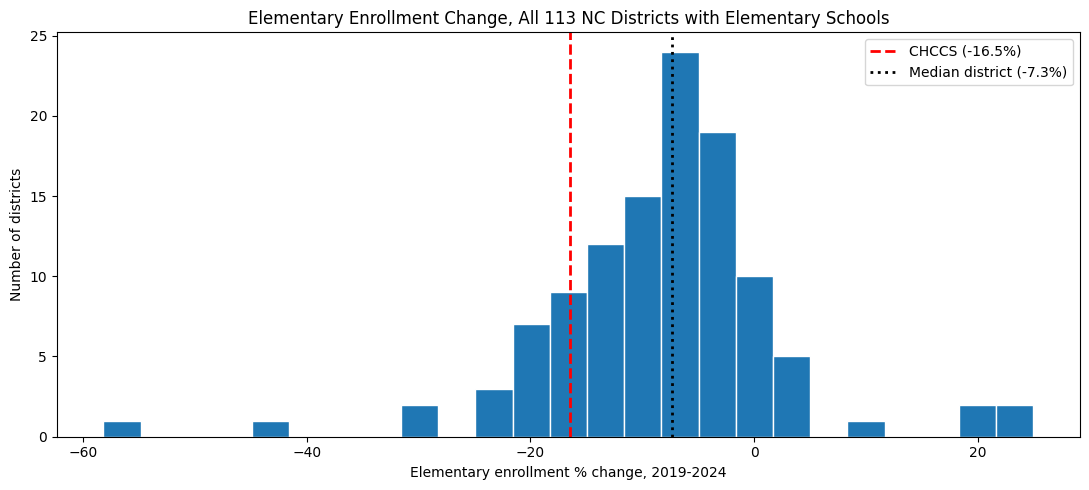

100 of 113 districts lost elementary enrollment 2019-2024.
16 districts declined more steeply than CHCCS; 96 declined less or grew.


In [51]:
# How unusual is CHCCS's elementary decline? This uses every district with
# elementary enrollment in both years -- no filtering.
#
# Worth stating why there's no filter, since an earlier draft of this
# analysis had one. It's tempting to drop districts that opened or closed an
# elementary school, on the theory that it distorts the comparison. It
# doesn't: this is a SUM across all of a district's elementary schools, so
# opening a 12th school just redistributes students already counted in the
# other 11. The district total barely moves. Filtering on school count would
# have discarded 26 districts to solve a problem that doesn't exist.
#
# The measurement issue that IS real -- elementary-aged kids in K-8 and K-12
# schools being invisible to this sum (Section 5) -- is handled by the
# sensitivity check above, which reruns this comparison three ways.
plt.figure(figsize=(11, 5))
plt.hist(elementary_change, bins=25, edgecolor="white")
plt.axvline(elementary_change["681LEA"], color="red", linestyle="--", linewidth=2,
            label=f"CHCCS ({elementary_change['681LEA']:.1f}%)")
plt.axvline(elementary_change.median(), color="black", linestyle=":", linewidth=2,
            label=f"Median district ({elementary_change.median():.1f}%)")
plt.xlabel("Elementary enrollment % change, 2019-2024")
plt.ylabel("Number of districts")
plt.title(f"Elementary Enrollment Change, All {len(elementary_change)} NC Districts with Elementary Schools")
plt.legend()
plt.tight_layout()
plt.show()

declining = (elementary_change < 0).sum()
worse_than_chccs = (elementary_change < elementary_change["681LEA"]).sum()
print(f"{declining} of {len(elementary_change)} districts lost elementary enrollment 2019-2024.")
print(f"{worse_than_chccs} districts declined more steeply than CHCCS; {len(elementary_change) - worse_than_chccs - 1} declined less or grew.")

### Synthesis

**Setup.** CHCCS closed an elementary school and is redistricting, citing declining enrollment. Why is enrollment declining?  Is enrollment falling because fewer children live in the district, or because fewer of the children who live here attend CHCCS?

**Tension.** The answer depends entirely on which number you look at, and the four nested layers disagree with each other in a revealing way:

| Layer | 2019 | 2024 | Change |
|---|---|---|---|
| Total population in the district | 93,239 | 93,897 | **+0.7%** |
| School-age population (5-17) | 13,065 | 12,309 | **-5.8%** |
| K-12 enrollment (ADM) | 12,335 | 11,266 | **-8.7%** |
| Elementary enrollment | 5,488 | 4,583 | **-16.5%** |

The community is not shrinking. It grew slightly. But its school-age population fell, its enrollment fell faster than that, and its *elementary* enrollment fell nearly three times faster than its school-age population. Each layer down, the decline gets steeper.

Two things drive the gap between those layers:

1. **Fewer school-age children**, which accounts for roughly two-thirds of the K-12 decline. Holding the 2019 capture rate fixed, the shrinking 5-17 population alone predicts a loss of about 714 students.
2. **A falling capture rate** -- the share of resident school-age children enrolled in CHCCS slipped from 0.944 to 0.915. That accounts for the remaining ~355 students, about a third of the decline.

And CHCCS's elementary decline is not typical. Across the 113 NC districts with elementary enrollment in both years, the median district lost 7.3%. CHCCS lost 16.5% -- more than double, ranking 17th steepest of 113, around the 15th percentile. That holds up under every way we tried slicing it (see the sensitivity check in Section 7): restricting to districts without combined-grade schools, or to districts whose grade structure didn't shift, moves CHCCS's percentile by at most two points.

**Resolution.** Population decline tells much of this story but not all of it, and it tells almost none of the elementary-specific story. The district has roughly the same number of residents, fewer children among them, fewer of those children enrolled, and the sharpest losses concentrated in its elementary schools -- where average school size fell from 499 to 417 students while the number of elementary schools stayed at 11. That is the arithmetic behind a closure decision, visible without any of the district's own projections.

**What we checked that didn't pan out.** Before landing here, we tested four other variables against enrollment change across all ~115 districts (Section 7): per-pupil expenditure, % economically disadvantaged, chronic absenteeism, and Pre-K enrollment. Only per-pupil expenditure correlated meaningfully (r = -0.62), and that turned out to be near-definitional rather than explanatory, since enrollment is its denominator. The other three were effectively uncorrelated (|r| < 0.17), including Pre-K enrollment, the one we expected to act as a leading indicator. Those null results are left in the notebook deliberately -- they're the reason we went looking for a population-based explanation instead.

## 9. What This Data Doesn't Tell Us

The findings in Section 8 come with real limits. These are grouped by how much they'd change the conclusion if someone pushed on them.

### Limits that could change the answer

- **There is no elementary-aged population figure, so the elementary story is half-finished.** SAIPE publishes ages 5-17 as a single block. That's enough to compute a capture rate for K-12, but not for elementary specifically. So we can show elementary enrollment falling nearly three times faster than the school-age population, but we cannot say how much of that gap is demographics versus school choice. This is the biggest open question in the notebook, and closing it needs ACS age-bracket data at school-district geography.
- **"Elementary enrollment" is a constructed measure with a blind spot.** DPI publishes no grade-level enrollment table, so elementary enrollment is built by summing schools labeled `E`. Elementary-aged children in K-8 and K-12 schools are invisible to that sum (Section 5). It's reliable for CHCCS, which has none, and unreliable for the eight districts where such schools hold over 20% of students. The statewide comparison was run three ways to check this didn't drive the result; it didn't.
- **Capture rate compares two different things.** ADM counts who attends; population counts who lives there. Children of district staff who live elsewhere inflate ADM without appearing in the denominator. That biases the capture rate upward, though it would only distort the *trend* if the size of that group changed materially over the period.

### Limits that affect precision, not direction

- **SAIPE figures are modeled estimates, not counts.** Census produces them with a statistical model and publishes error guidance; the margins are wider for small districts. The one-third of the decline attributed to falling capture rate is a rough split, not a precise one.
- **The year alignment is close but not exact.** SAIPE measures population as of July 1; DPI's year label refers to the school year ending that June. Our pairings are consistent across both endpoints, so percent changes hold, but a ratio like capture rate inherits roughly a one-month offset.
- **Three different comparison windows appear in this notebook, on purpose.** Section 5's first look uses 2006-2025 (ADM's full history). The multi-variable comparison uses 2019-2025, set by per-pupil expenditure's start date. The population and elementary work uses 2019-2024, because SAIPE stops at 2024. These are not interchangeable, and quoting a number from one against another would be a mistake.
- **Percent change is sensitive to its endpoints.** Section 5 showed this directly: CHCCS looks flat over 2006-2025 (+0.8%) and clearly declining over 2019-2025 (-10.3%). Same district, same data, different window.
- **Masking removes small districts.** DPI suppresses counts under 10, which is why 10 of 115 districts dropped out of Section 6's merged table. Statewide claims here lean toward larger districts.

### Things this data cannot address at all

- **Why families chose something other than CHCCS.** The capture-rate gap is a size, not an explanation. Charter, private, homeschool, and families priced out of the area are indistinguishable in this data.
- **Causation between districts.** Section 7's correlations run across ~115 districts without controlling for region, local economy, or urban/rural status. Any of those could move two variables together without either affecting the other. The per-pupil expenditure correlation (r = -0.62) is the clearest example of a relationship that is arithmetic rather than causal, since enrollment is its denominator.
- **How ADM is measured.** Still unresolved from Section 4. DPI publishes no methodology for it, so every figure built on ADM inherits that open question.


## 10. Ethical Considerations and Insights Discussion

### Whose numbers these are

Every figure in this notebook is a count of children. The 1,069-student decline is 1,069 families who made a decision or moved away. The 16.5% elementary drop is the reason a school is closing, which means a neighborhood loses a building, some kids change schools, and some teachers lose jobs. That doesn't make the analysis wrong, but it does mean the numbers shouldn't be discussed as though they're inventory.

### Measurement bias: is ADM the right thing to count?

ADM measures attendance-based membership. It's a good proxy for "how many students does this district serve," and a poor proxy for most things people care about — whether a school is good, whether a community values it, whether closing it is wise. The closure study leans on enrollment and building capacity because those are measurable, not because they're the whole picture. A school can be under-enrolled and still be the thing holding a neighborhood together. This analysis can measure the first and says nothing about the second.

### Representation: who's invisible here

The most important number in this notebook — the roughly one-third of the decline not explained by population — is made entirely of people we can't see. A resident child who enrolls in a charter, goes private, gets homeschooled, or whose family left over housing costs all look identical in this data: an absence. We can size that gap but not open it.

DPI's masking rule compounds this. Suppressing any count under 10 protects student privacy, which is the right call, but it means small districts and small subgroups systematically drop out of analyses like this one. Ten of 115 districts fell out of Section 6's merged table for exactly that reason. The picture tilts toward larger districts, and any statewide claim here inherits that tilt.

### Privacy: FERPA and why this stays clear of it

FERPA governs student education records, and student-level data is where the real privacy risk sits. Everything used here is aggregate and already public — district and school totals DPI publishes for researchers, Census estimates, and a school board's own presentation. No individual student appears anywhere in this notebook, and nothing here could be used to identify one. That's a deliberate boundary, not an accident of what was available.

### Transparency: what we did to make this checkable

Every number traces to a file in `data_sources/`, indexed in `INDEX.md`. The one piece of nontrivial data engineering — matching DPI's district codes to Census's — lives in its own documented script rather than buried in a notebook cell. Where a choice could have changed the answer, we ran it several ways and published the comparison rather than picking one quietly (Section 7's sensitivity check). Where we found our own errors, we corrected them in place rather than deleting the evidence.

### What the insights actually mean, and what they don't

The data supports the district's premise. Enrollment is falling, it's falling faster than the school-age population, and elementary is falling fastest of all — more than double the statewide median. If the question is "is CHCCS's stated problem real," the answer is yes.

But the data does not validate any particular response to that problem. It can't say which school should close, whether closing one is better than redistricting, or how the cost should fall across neighborhoods. Those are value judgments about who absorbs a loss, and no enrollment table settles them. A 16.5% decline is an argument that something has to change; it is not an argument for any specific change.

The gap this analysis leaves open is the one that matters most for policy. Two-thirds of the decline is demographics — fewer children, which a school district cannot do much about. One-third is children who live here and enroll elsewhere, which a district might be able to do something about, if it knew why. This data can measure that third. It cannot explain it. Anyone using this analysis to argue for a particular decision should be clear about which of those two they think they're addressing.
